## **1. Setup the Environment**
This cell downloads LoRaSim, installs Python 2, and the necessary dependencies.
Run this cell first.

In [1]:
# ! wget https://www.lancaster.ac.uk/scc/sites/lora/lorasim-20170710.tgz -O lorasim-20170710.tgz
# ! tar -xzf lorasim-20170710.tgz # Use -xzf for .tgz

# # Install Python 2 and pip for Python 2
# !sudo apt-get update -q
# !sudo apt-get install python2 python2-dev -q
# !curl https://bootstrap.pypa.io/pip/2.7/get-pip.py -o get-pip.py
# !sudo python2 get-pip.py
# !rm get-pip.py

# # Install Python Tkinter for matplotlib backend (if needed, though Agg should avoid it)
# !sudo apt-get install python-tk -q

# # Install dependencies using pip for Python 2
# !pip2 install -r 'lorasim/requirements.txt' --ignore-installed six # Added --ignore-installed six for potential conflicts

# print("\n--- Environment Setup Complete ---")

## **2. Import Libraries and Define Simulation Functions**
Import standard libraries and define the core `simulate` function
capable of calling both LoRaSim scripts, along with the `aloha_der` function.

In [2]:
import os
import pandas as pd
import math
import subprocess
import matplotlib
import matplotlib.pyplot as plt

print(f"Using Matplotlib version: {matplotlib.__version__}") # Check matplotlib version

# Store original MPLBACKEND if it exists
original_mplbackend = os.environ.get("MPLBACKEND", None)

def simulate(n_nodes, tx_rate, exp, duration, nrBS=1, use_multi_bs_script=False, collision=True):
    """
    Runs the LoRaSim simulation.

    Args:
        n_nodes (int): Number of nodes (total nodes if multi-bs).
        tx_rate (float): Average send interval (ms).
        exp (int): Experiment number (0-5 for loraDir, 0-4 for loraDirMulBS).
        duration (int): Simulation time (ms).
        nrBS (int): Number of base stations (used only if use_multi_bs_script is True).
        use_multi_bs_script (bool): If True, calls loraDirMulBS.py, otherwise loraDir.py.
        collision (bool): Whether to use full collision check (True) or simplified (False).
    """
    env = os.environ.copy()
    # Set MPLBACKEND to Agg to prevent Tkinter issues in non-GUI environments
    env["MPLBACKEND"] = "Agg"

    command = ["python2"]
    script_to_run = "lorasim/loraDirMulBS.py" if use_multi_bs_script else "lorasim/loraDir.py"
    command.append(script_to_run)

    command.extend([
        str(int(n_nodes)),
        str(int(tx_rate)),
        str(int(exp)),
        str(int(duration)),
    ])

    if use_multi_bs_script:
        command.append(str(int(nrBS)))

    # Add collision argument - assumes it's the last optional argument for both scripts
    command.append("1" if collision else "0")

    print(f"Running command: {' '.join(command)}") # Debug print

    try:
        result = subprocess.run(
            command,
            env=env,
            capture_output=True,
            text=True,  # Capture output as text
            check=False # Don't raise exception on non-zero exit code immediately
        )

        # Print stdout/stderr for debugging purposes
        # print("STDOUT:\n", result.stdout)
        # print("STDERR:\n", result.stderr)


        if result.returncode != 0:
             print(f"Warning: Simulation command exited with code {result.returncode}")
             print(f"STDERR for error check:\n{result.stderr[:500]}...") # Print beginning of stderr
             # Optionally, decide if this error should stop the process
             # raise Exception(f"Simulation failed: {result.stderr}")

    except FileNotFoundError:
        print(f"Error: Python 2 executable not found or script '{script_to_run}' missing.")
        raise # Re-raise the error to stop execution
    except Exception as e:
        print(f"An unexpected error occurred running the simulation: {e}")
        raise # Re-raise

    finally:
      # Restore original MPLBACKEND if it existed
      if original_mplbackend:
          os.environ["MPLBACKEND"] = original_mplbackend
      elif "MPLBACKEND" in os.environ:
          # If it wasn't set before, remove the temporary setting
          del os.environ["MPLBACKEND"]


# Define aloha_der function for theoretical comparison
def aloha_der(n_nodes, t, packet_rate_per_node=1e-6):
    """
    Calculates theoretical Aloha DER (S/G = e^-2G).

    Args:
        n_nodes (int): Number of nodes.
        t (float): Packet airtime in milliseconds.
        packet_rate_per_node (float): Average packets per millisecond per node.
    """
    # G = N * lambda * t (lambda is packet rate per node, t is airtime)
    # Ensure t is treated as milliseconds if rate is per ms
    G = n_nodes * packet_rate_per_node * t
    return math.exp(-2 * G)

print("--- Helper Functions Defined ---")

Using Matplotlib version: 3.7.5
--- Helper Functions Defined ---


## **3. Run Simulations**
Execute the simulation loops required for both Figure 5 and Figure 7.
This will take a considerable amount of time.

In [3]:
# --- Simulation Parameters ---
duration = 86400000 # 24 hours in ms
tx_rate = 1e6      # 1 packet per 1,000,000 ms (approx. 16.7 min average interval)
collision_check = True # Use full collision model for both figures

# Node counts to simulate (adjust range/step as needed for time vs resolution)
nodes_list = list(range(1,10, 2)) + list(range(10,100,10)) + list(range(100, 500, 50)) + list(range(500, 1700, 200))
# nodes_list = list(range(10, 110, 10)) # Faster list for testing

# --- Run Simulations for Figure 5 (Dynamic Parameters, Single Sink) ---
print("\n--- Running Simulations for Figure 5 ---")
exps_fig5 = [4, 3, 5] # SN3 (static), SN4 (dyn airtime), SN5 (dyn airtime+TP)
for exp_fig5 in exps_fig5:
    print(f"\nRunning experiment {exp_fig5} for Figure 5...")
    # Clear previous file for this experiment
    fname = f"exp{exp_fig5}.dat"
    if os.path.exists(fname):
        try: os.remove(fname)
        except OSError as e: print(f"Error removing {fname}: {e}")

    for n_nodes in nodes_list:
      print(f"  Simulating {n_nodes} nodes (Exp {exp_fig5})...")
      simulate(n_nodes, tx_rate, exp_fig5, duration, nrBS=1, use_multi_bs_script=False, collision=collision_check)
print("--- Figure 5 Simulations Complete ---")


# --- Run Simulations for Figure 7 (Multiple Sinks, Static SN1) ---
print("\n--- Running Simulations for Figure 7 ---")
exp_fig7 = 0 # Experiment 0 corresponds to SN1 used in Fig 7
base_station_counts_fig7 = [1, 2, 3, 4, 8, 24] # As shown in Figure 7
for bs_count in base_station_counts_fig7:
    print(f"\nRunning experiment {exp_fig7} for Figure 7 with {bs_count} Base Station(s)...")
    # Clear previous file for this BS count
    fname = f"exp{exp_fig7}BS{bs_count}.dat"
    if os.path.exists(fname):
       try: os.remove(fname)
       except OSError as e: print(f"Error removing {fname}: {e}")

    for n_nodes in nodes_list:
        # Important: n_nodes for loraDirMulBS.py is TOTAL nodes
        print(f"  Simulating {n_nodes} total nodes ({bs_count} BS)...")
        simulate(n_nodes, tx_rate, exp_fig7, duration, nrBS=bs_count, use_multi_bs_script=True, collision=collision_check)
print("--- Figure 7 Simulations Complete ---")


--- Running Simulations for Figure 5 ---

Running experiment 4 for Figure 5...
  Simulating 1 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 1 1000000 4 86400000 1
  Simulating 3 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 3 1000000 4 86400000 1
  Simulating 5 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 5 1000000 4 86400000 1
  Simulating 7 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 7 1000000 4 86400000 1
  Simulating 9 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 9 1000000 4 86400000 1
  Simulating 10 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 10 1000000 4 86400000 1
  Simulating 20 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 20 1000000 4 86400000 1
  Simulating 30 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 30 1000000 4 86400000 1
  Simulating 40 nodes (Exp 4)...
Running command: python2 lorasim/loraDir.py 40 1000000 4 86400000 1
  Simulating 50 nodes

## **4. Process Results and Generate Plots**
Load the `.dat` files generated by the simulations, calculate Data Extraction Rate (DER),
and plot the results to reproduce Figure 5 and Figure 7.


--- Processing and Plotting Results ---
Processing Figure 5 data...
Loaded and processed exp4.dat
Loaded and processed exp3.dat
Loaded and processed exp5.dat


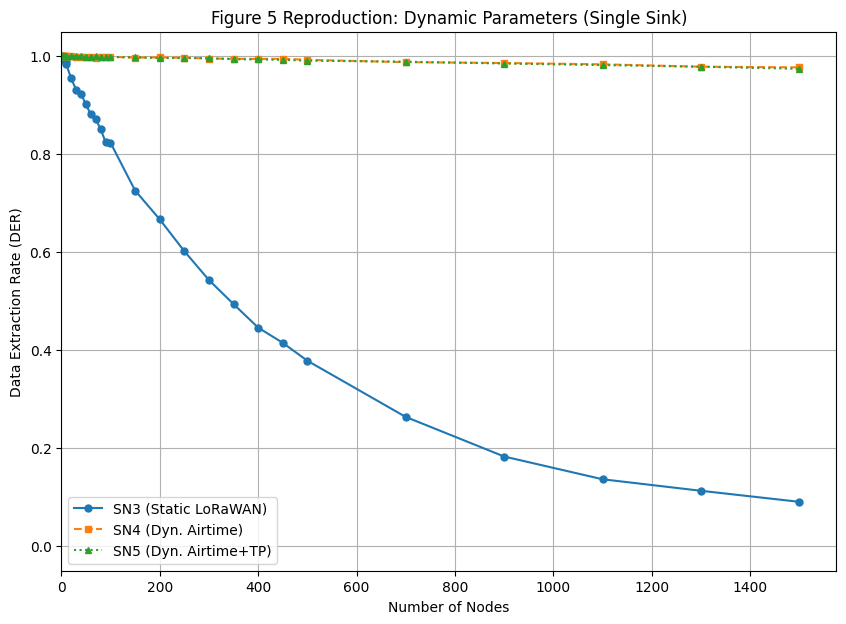


Processing Figure 7 data...
Loaded and processed exp0BS1.dat
Loaded and processed exp0BS2.dat
Loaded and processed exp0BS3.dat
Loaded and processed exp0BS4.dat
Loaded and processed exp0BS8.dat
Loaded and processed exp0BS24.dat


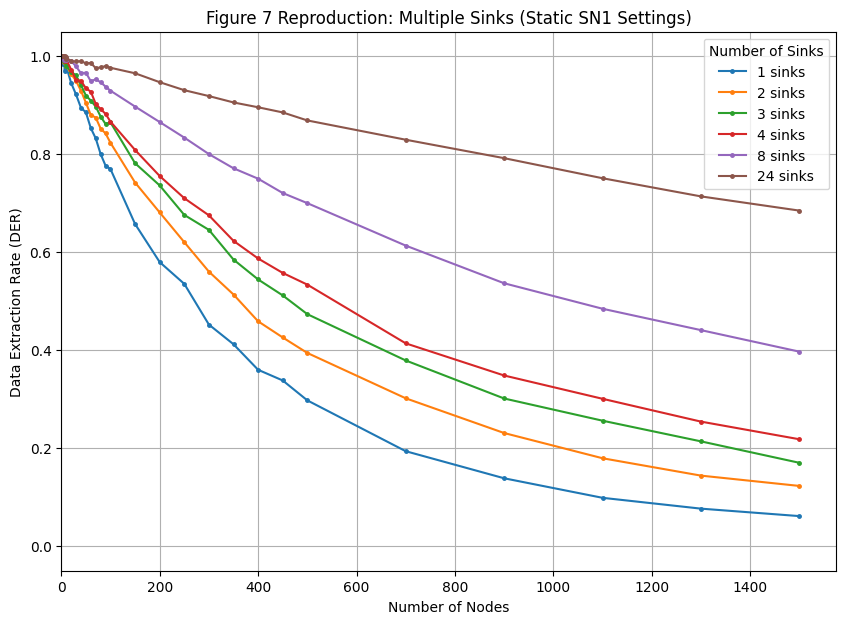


--- Script Finished ---


In [4]:
print("\n--- Processing and Plotting Results ---")

# --- Process and Plot Figure 5 ---
plt.figure(figsize=(10, 7))
print("Processing Figure 5 data...")
exps_fig5 = [4, 3, 5]
labels_fig5 = {4: "SN3 (Static LoRaWAN)", 3: "SN4 (Dyn. Airtime)", 5: "SN5 (Dyn. Airtime+TP)"}
markers = {4: 'o', 3: 's', 5: '^'}
linestyles = {4: '-', 3: '--', 5: ':'}

fig5_data_loaded = False
for exp_fig5 in exps_fig5:
    fname = f"exp{exp_fig5}.dat"
    try:
        # loraDir.py output: #nrNodes nrCollisions nrTransmissions OverallEnergy
        df = pd.read_csv(fname, sep=" ", comment='#', names=["#nrNodes", "nrCollisions", "nrTransmissions", "OverallEnergy"], header=None, skipinitialspace=True)
        # Ensure transmissions > 0 to avoid division by zero
        df = df[df["nrTransmissions"] > 0].copy()
        # Calculate DER = Received / Transmitted = (Transmitted - Collisions) / Transmitted
        # Note: nrCollisions might count packets involved in *any* collision, not just lost ones.
        # The paper defines DER based on successfully received packets. The script output might need careful interpretation.
        # Let's assume (Transmitted - Collisions) is a proxy for received for now, based on loraDir.py logic.
        df["der"] = (df["nrTransmissions"] - df["nrCollisions"]) / df["nrTransmissions"]
        # Ensure DER is not negative (can happen if collisions exceed transmissions due to error/counting method)
        df["der"] = df["der"].clip(lower=0)

        # Check for empty dataframe after filtering
        if df.empty:
            print(f"  Warning: No data with transmissions > 0 found in {fname}. Skipping plot for this experiment.")
            continue

        plt.plot(df["#nrNodes"], df["der"], label=labels_fig5[exp_fig5], marker=markers[exp_fig5], linestyle=linestyles[exp_fig5], markersize=5)
        fig5_data_loaded = True
        print(f"Loaded and processed {fname}")

    except FileNotFoundError:
        print(f"  Warning: Data file not found for Figure 5, experiment {exp_fig5} ({fname}). Skipping plot for this experiment.")
    except pd.errors.EmptyDataError:
         print(f"  Warning: Data file {fname} is empty. Skipping plot for this experiment.")
    except Exception as e:
        print(f"  Error processing file {fname}: {e}")

if fig5_data_loaded:
    plt.title("Figure 5 Reproduction: Dynamic Parameters (Single Sink)")
    plt.xlabel("Number of Nodes")
    plt.ylabel("Data Extraction Rate (DER)")
    plt.ylim(-0.05, 1.05)
    plt.xlim(left=0)
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No data successfully loaded for Figure 5, plot skipped.")


# --- Process and Plot Figure 7 ---
plt.figure(figsize=(10, 7))
print("\nProcessing Figure 7 data...")
exp_fig7 = 0 # SN1 settings
base_station_counts_fig7 = [1, 2, 3, 4, 8, 24]
fig7_data_loaded = False

for bs_count in base_station_counts_fig7:
    fname = f"exp{exp_fig7}BS{bs_count}.dat"
    try:
        # loraDirMulBS.py output: # nrNodes DER (DER is already calculated)
        df = pd.read_csv(fname, sep=" ", comment='#', names=["#nrNodes", "DER"], header=None, skipinitialspace=True)
        # Ensure DER is not negative
        df["DER"] = df["DER"].clip(lower=0)

        # Check for empty dataframe
        if df.empty:
            print(f"  Warning: No data found in {fname}. Skipping plot for this configuration.")
            continue

        plt.plot(df["#nrNodes"], df["DER"], label=f"{bs_count} sinks", marker='.', linestyle='-', markersize=5)
        fig7_data_loaded = True
        print(f"Loaded and processed {fname}")

    except FileNotFoundError:
         print(f"  Warning: Data file not found for Figure 7, {bs_count} base stations ({fname}). Skipping plot for this configuration.")
    except pd.errors.EmptyDataError:
         print(f"  Warning: Data file {fname} is empty. Skipping plot for this configuration.")
    except Exception as e:
        print(f"  Error processing file {fname}: {e}")


if fig7_data_loaded:
    plt.title("Figure 7 Reproduction: Multiple Sinks (Static SN1 Settings)")
    plt.xlabel("Number of Nodes")
    plt.ylabel("Data Extraction Rate (DER)")
    plt.ylim(-0.05, 1.05)
    plt.xlim(left=0)
    plt.legend(title="Number of Sinks")
    plt.grid(True)
    plt.show()
else:
    print("No data successfully loaded for Figure 7, plot skipped.")


print("\n--- Script Finished ---")